<h1> Import cell

In [11]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.linear_model import LinearRegression,Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from prettytable import PrettyTable
from utils import stats, exploration_plots, compare_distributions, compare_categorical_distributions, boxplot_features, correlation_matrix
import preprocessing
importlib.reload(preprocessing)
from preprocessing import preprocessing_dev, preprocessing_eval
import sys
import importlib
from sklearn.preprocessing import StandardScaler
import re
from catboost import CatBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR


ImportError: cannot import name 'boxplot_features' from 'utils' (/Users/giulianaparadiso/Desktop/PoliTo/Data science lab/Progetto/data-science-lab-project/utils.py)

<h1> Datasets loading

In [3]:
df = pd.read_csv("development.csv", header="infer")
evaluate_df = pd.read_csv("evaluation.csv", header="infer")

<h1> Data exploration

In [4]:
print(df.shape)
print(evaluate_df.shape)

(79589, 21)
(19898, 20)


In [5]:
missing_per_feature = df.isnull().sum()
print(missing_per_feature)

category            0
title               0
body                0
amenities       12804
bathrooms          51
bedrooms           89
currency            0
fee                 0
has_photo           0
pets_allowed    48320
price               0
price_type          0
square_feet         0
address         73226
cityname          234
state             234
latitude           23
longitude          23
source              0
time                0
id                  0
dtype: int64


In [6]:
missing_per_feature = evaluate_df.isnull().sum()
print(missing_per_feature)

category            0
title               0
body                0
amenities        3240
bathrooms          11
bedrooms           34
currency            0
fee                 0
has_photo           0
pets_allowed    12102
price_type          0
square_feet         0
address         18320
cityname           68
state              68
latitude            2
longitude           2
source              0
time                0
id                  0
dtype: int64


<h1> Data exploration - Plots

<h2> Geographical distribution of apartments

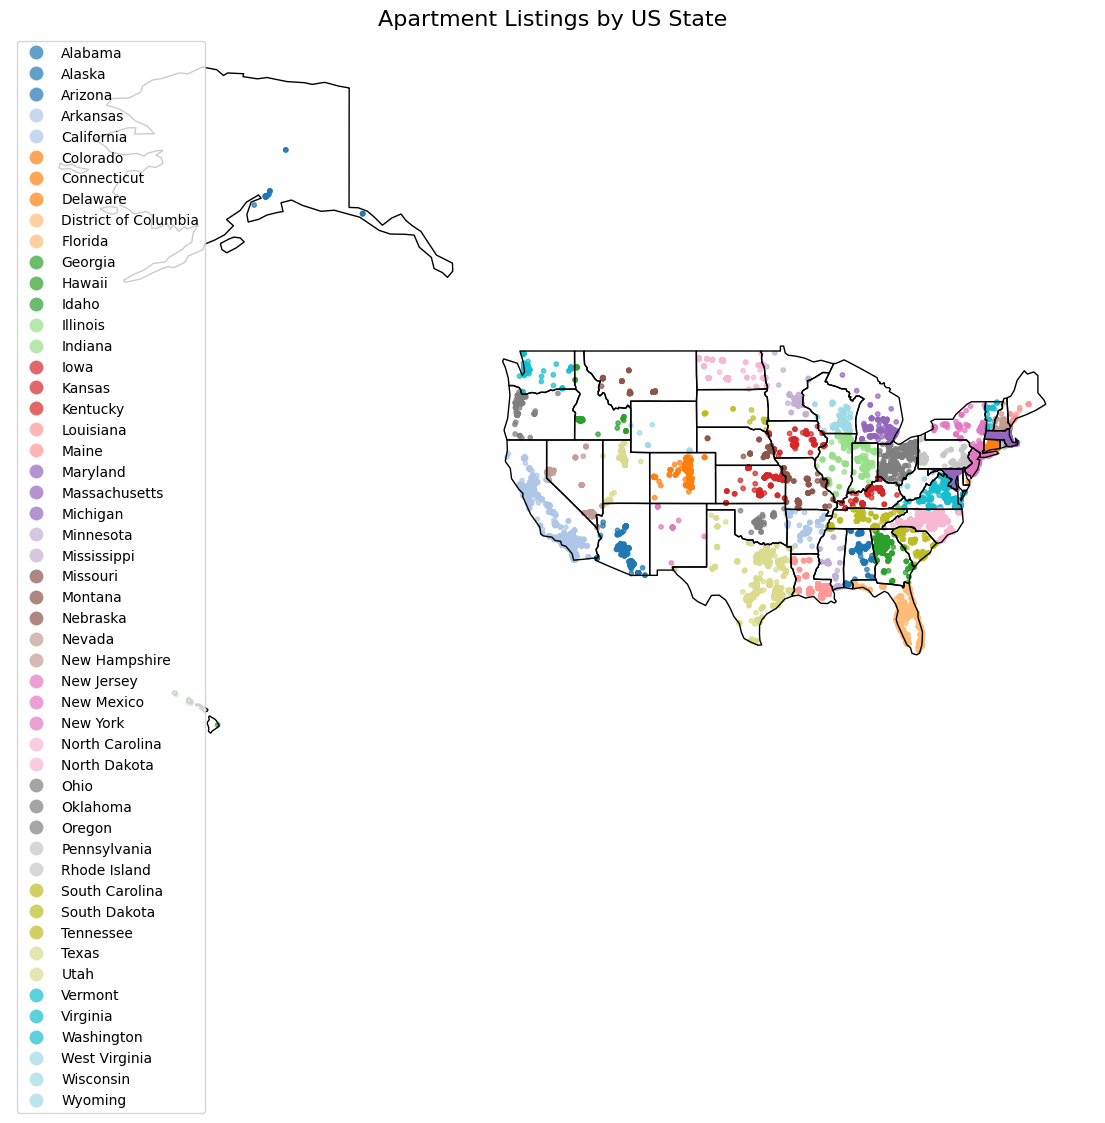

In [ ]:
import geopandas as gpd

world = gpd.read_file("geopandas_files/countries/ne_110m_admin_0_countries.shp")
usa = world[world['NAME'] == 'United States of America']

# Carica un dataset con i confini degli stati USA
# Se non hai un file, puoi usare uno come questo (usa-census states shapefile)
states = gpd.read_file('geopandas_files/states/ne_110m_admin_1_states_provinces.shp')  # <-- Modifica con il tuo file

# Carica il tuo dataset con latitude e longitude
#df = pd.read_csv('your_data.csv')  # <-- Inserisci il tuo file CSV

# Crea un GeoDataFrame dai tuoi punti
gdf_points = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df['longitude'], df['latitude']),
    crs="EPSG:4326"
)

# Assicurati che i CRS siano allineati
states = states.to_crs(epsg=4326)
gdf_points = gdf_points.to_crs(epsg=4326)

# Spatial join per associare ogni punto allo stato in cui si trova
gdf_points_with_state = gpd.sjoin(gdf_points, states, how='left', predicate='within')

# Crea il plot
fig, ax = plt.subplots(1, 1, figsize=(14, 10))

# States booundaries
states.boundary.plot(ax=ax, linewidth=1, color='black')

# Colora i punti in base allo stato (assumendo che il nome dello stato sia nella colonna 'NAME')
gdf_points_with_state.plot(
    ax=ax,
    column='name',  # o usa il nome effettivo della colonna con i nomi degli stati
    cmap='tab20',
    markersize=10,
    alpha=0.7,
    legend=True
)

ax.set_title('Apartment Listings by US State', fontsize=16)
ax.set_axis_off()
plt.show()



<h2> Normalized frequency distribution of numerical features

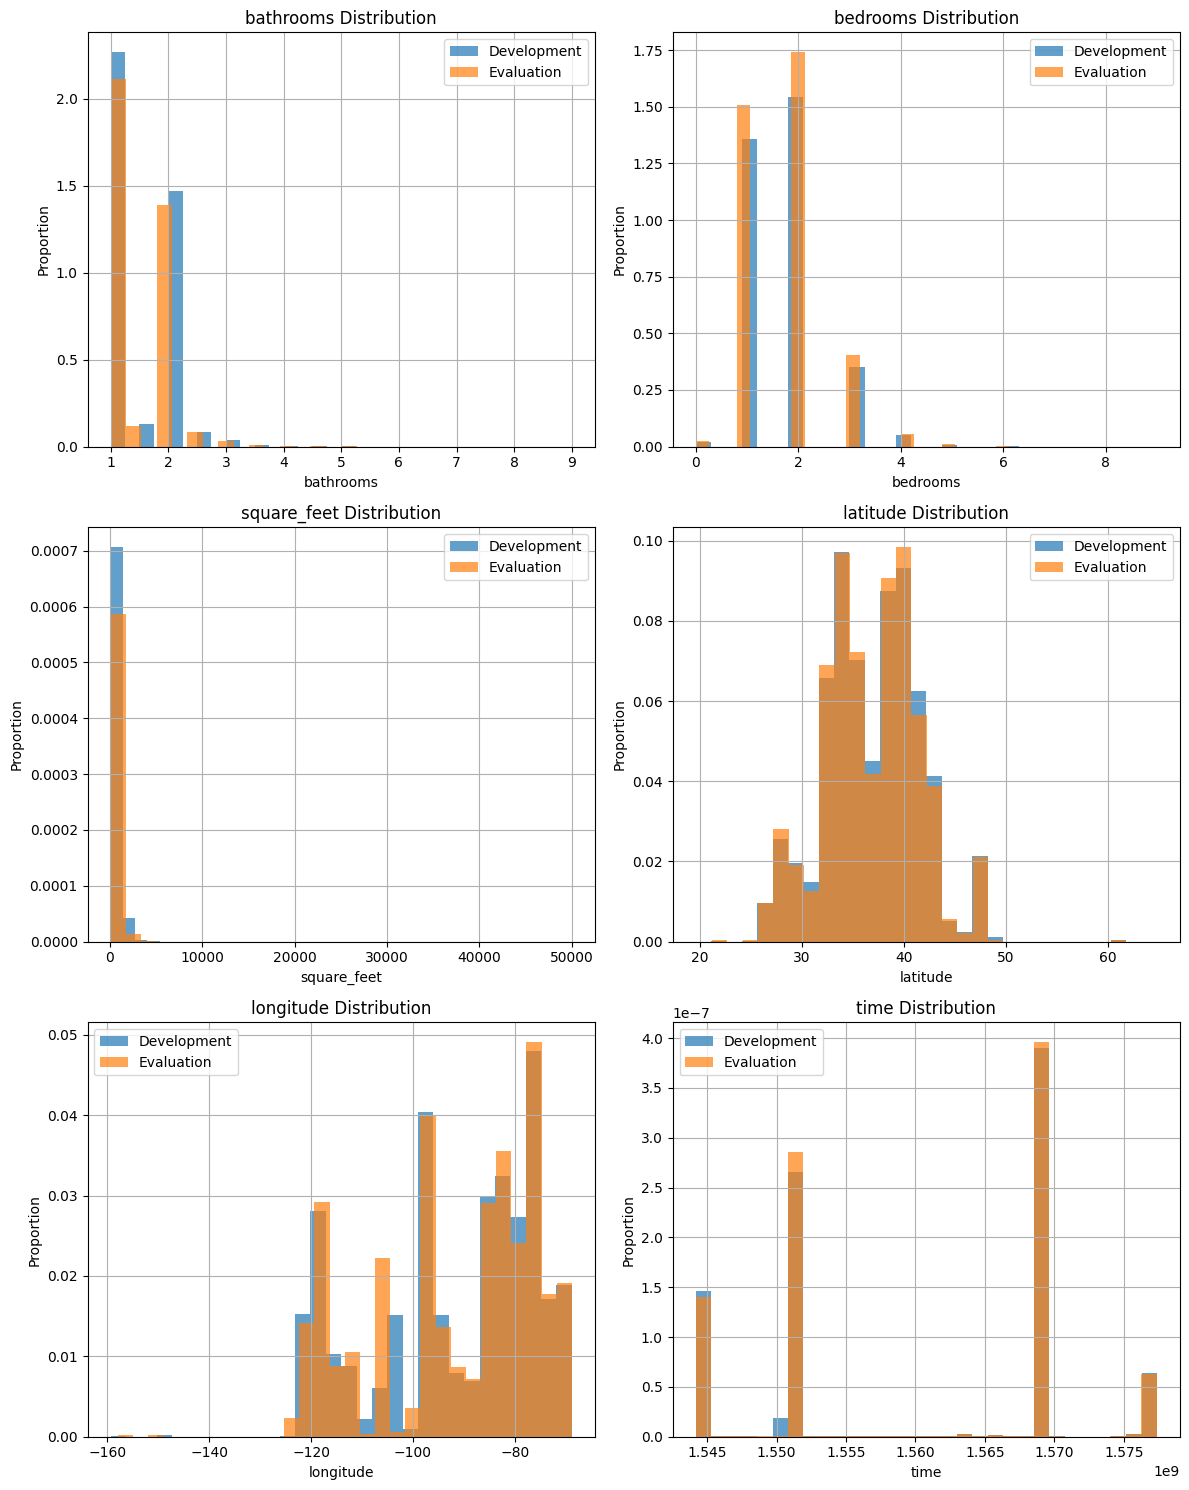

In [9]:
df_plot = df.drop(columns=['price'])
compare_distributions(df_plot, evaluate_df)

<h2> Normalized frequency distribution of categorical features

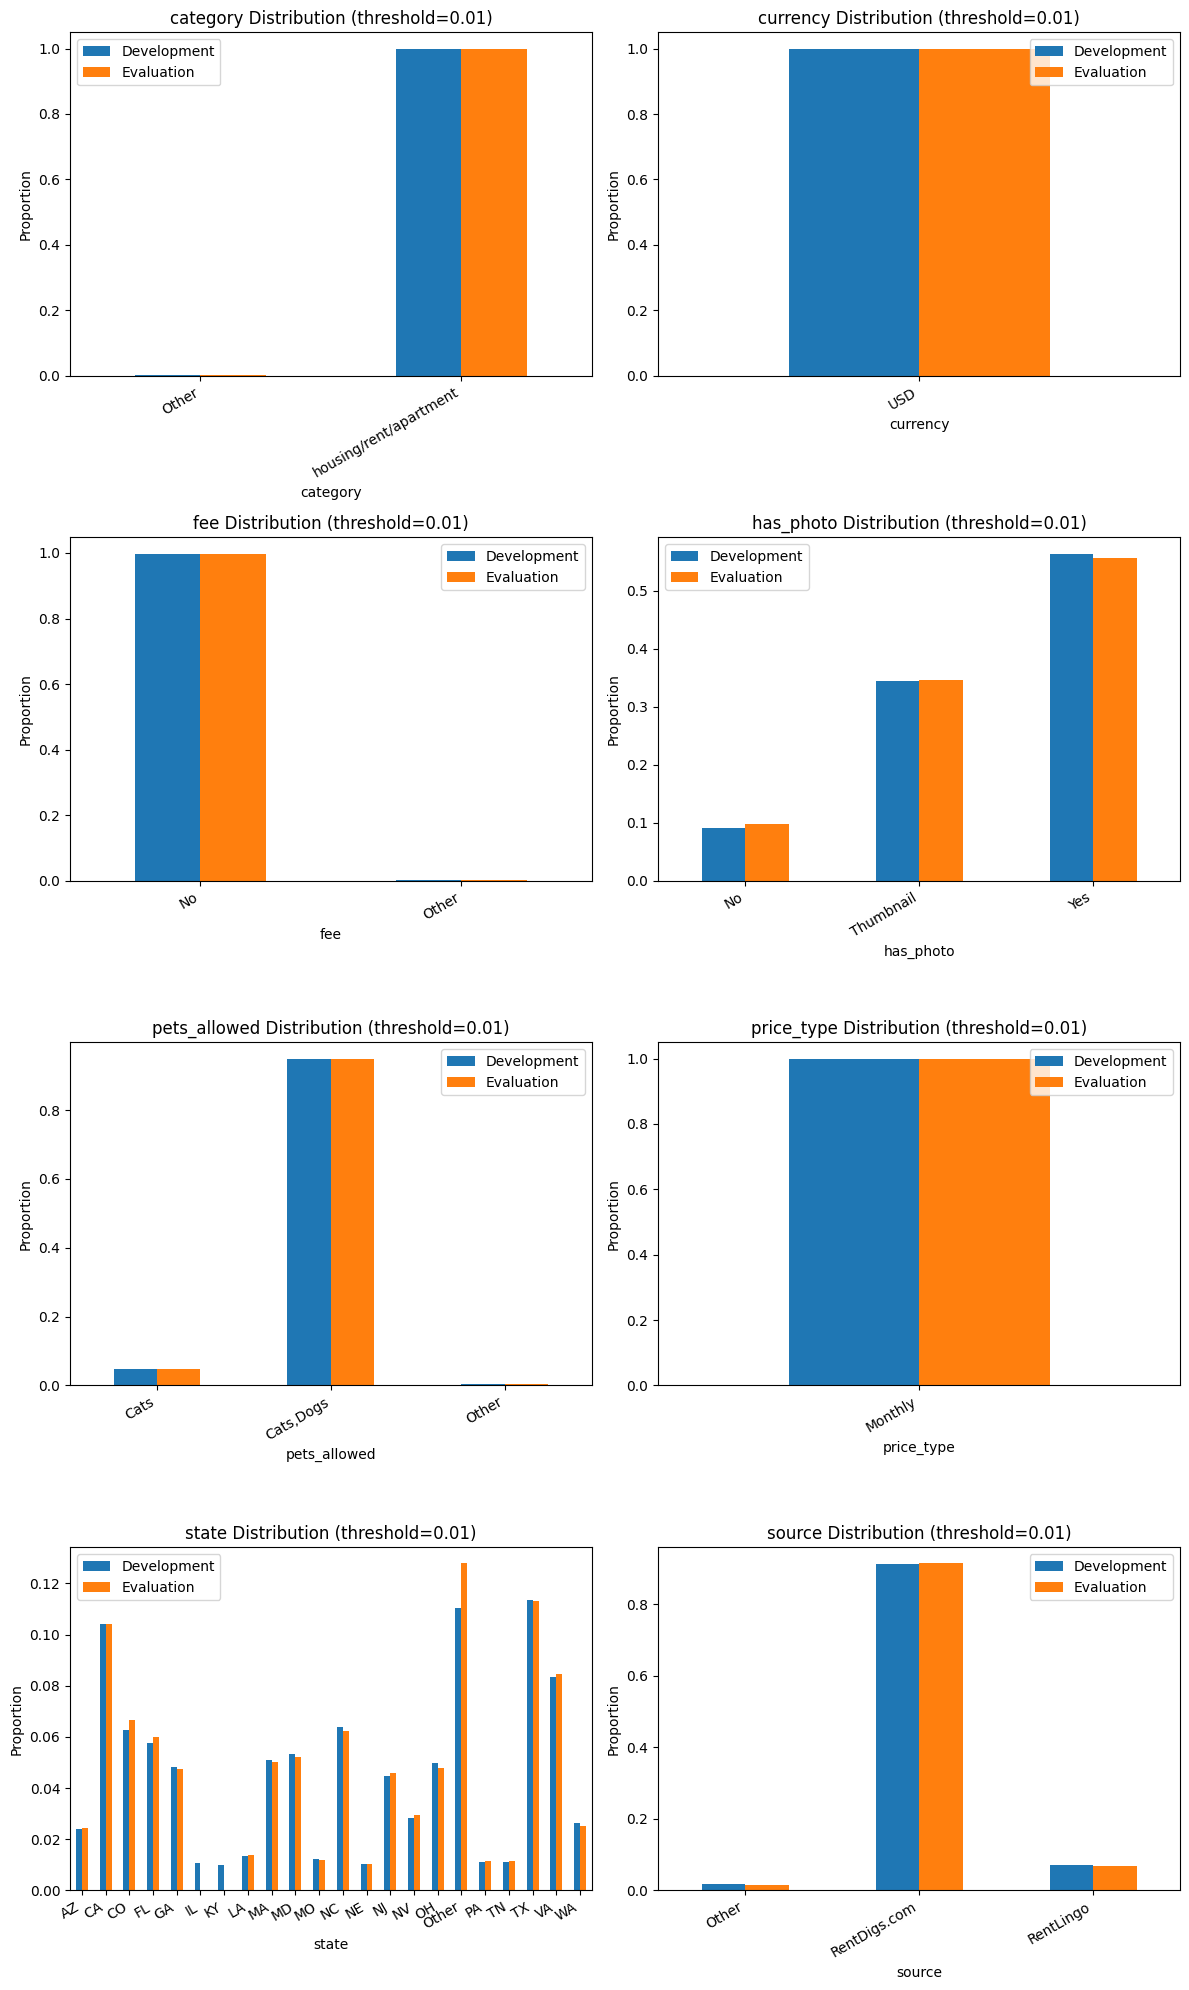

In [8]:
df_plot_cat = df.drop(columns=['price', 'id','amenities','title','body','address','cityname'])
df_eval_plot_cat = evaluate_df.drop(columns=['id','amenities','title','body','address','cityname'])
compare_categorical_distributions(df_plot_cat, df_eval_plot_cat)

<h2> Boxplots

In [ ]:
boxplot_features(df_plot, evaluate_df)

<h1> Correlation matrix heatmap

In [ ]:
correlation_matrix(df_plot)

In [ ]:
# Filtra le righe dove latitude o longitude mancano
missing_geo = evaluate_df[evaluate_df['latitude'].isnull() | evaluate_df['longitude'].isnull()]

# Stampa le colonne body e title per quelle righe
for idx, row in missing_geo.iterrows():
    print(f"Index: {idx}")
    print("Body:")
    print(row['body'])

    print("\nTitle:")
    print(row['title'])

    print("-"*50)

Index: 5066
Body:
Shores, you will enjoy an unrivaled lifestyle within the tranquil setting of the Chesapeake Bay with all the conveniences of Virginia Beach Town Center and the Oceanfront. We are minutes away from highly desirable schools, award-winning restaurants, shopping, s, entertainment and fabulous nightlife. Shores also provides residents the convenience of being situated adjacent to many businesses and restaurants. Unwind in a NEWLY REMODELED apartment home designed to include lavish interiors and rich amenities that provide a lifestyle you merely dreamed of. These stunning apartment homes range from expansive one, 2 and 3 beds units. At Shores you will benefit from the max in comfort and convenience. Located 1 block from the beach our Virginia Beach rentals are steps from the for all the summertime fun you can enjoy. More units available: three Bd / 2 Bedrooms 1,316 square ft for $1,705/mo | one Bd / 2 Bedrooms 1,078 sq. feet for $1,554/mo | two Bd / 2 Bedrooms 859 sq.

Titl

In [10]:
def fill_missing_geo(df):
    """
    Riempie cityname, state, latitude e longitudine mancanti in df
    utilizzando le informazioni nel testo (body, title) e le medie per city+state dal dataset stesso.
    """
    df = df.copy()

    # Filtra le righe dove mancano latitude o longitudine
    missing_geo = df[df['latitude'].isnull() | df['longitude'].isnull()]
    print(f"Righe mancanti: {len(missing_geo)}")

    # Elenca tutte le cityname per trovare eventuali match
    city_vals = df['cityname'].dropna().unique()

    for idx, row in missing_geo.iterrows():
        text = f"{row['body']} {row['title']}"

        # Cerca se nel testo compare il nome di una delle city
        matching_cities = [c for c in city_vals if c.lower() in text.lower()]
        
        if matching_cities:
            matching_city = matching_cities[0]
            df.at[idx, 'cityname'] = matching_city

            # Cerca lo state corrispettivo dalla tabella
            matching_state = df.loc[df['cityname']==matching_city, 'state'].mode()
            if not matching_state.empty:
                matching_state = matching_state[0]
                df.at[idx, 'state'] = matching_state

                # Calcola media delle coordinate per quella city+state dal dataset
                filter_df = df[
                    (df['cityname']==matching_city) & 
                    (df['state']==matching_state) & 
                    (df['latitude'].notnull()) & 
                    (df['longitude'].notnull())]

                if not filter_df.empty:
                    mean_lat = filter_df['latitude'].mean()
                    mean_lon = filter_df['longitude'].mean()

                    df.at[idx, 'latitude'] = mean_lat
                    df.at[idx, 'longitude'] = mean_lon

                    print(f"Aggiornato idx {idx} -> city:{matching_city} state:{matching_state} latitude:{mean_lat}longitude:{mean_lon}")

                else:
                    print(f"Nessun match per media delle coordinate per {matching_city}")

        else:
            print(f"Nessun nome di city individuato nel testo per l'indice {idx}")

    return df


In [11]:
# Esempio d'uso:
evaluate_df = fill_missing_geo(evaluate_df)

Righe mancanti: 2
Aggiornato idx 5066 -> city:Virginia Beach state:VA latitude:36.82976625longitude:-76.08738625
Nessun nome di city individuato nel testo per l'indice 8541


In [12]:
df = fill_missing_geo(df)

Righe mancanti: 23
Nessun nome di city individuato nel testo per l'indice 8425
Aggiornato idx 10656 -> city:Chesapeake state:VA latitude:36.731518248175185longitude:-76.26091167883212
Aggiornato idx 11734 -> city:Virginia Beach state:VA latitude:36.83509516129032longitude:-76.10037473118278
Aggiornato idx 12452 -> city:Virginia Beach state:VA latitude:36.83509516129032longitude:-76.1003747311828
Aggiornato idx 15002 -> city:Shelby state:OH latitude:40.8888longitude:-82.6625
Aggiornato idx 20320 -> city:Tea state:SD latitude:43.4468longitude:-96.8378
Aggiornato idx 24355 -> city:Falls Church state:VA latitude:38.87584215686274longitude:-77.17635882352941
Aggiornato idx 26475 -> city:Virginia Beach state:VA latitude:36.83509516129032longitude:-76.1003747311828
Aggiornato idx 26942 -> city:Reno state:NV latitude:39.48905839694657longitude:-119.82507709923664
Aggiornato idx 29075 -> city:Chesapeake state:VA latitude:36.731518248175185longitude:-76.26091167883212
Aggiornato idx 33631 -> cit

<h1> Preprocessing

In [22]:
df = preprocessing_dev(df)
evaluate_df = preprocessing_eval(df,evaluate_df)
y = df["price"]
df.drop(columns=["price","square_feet_quantile"], inplace=True)
evaluate_df.drop(columns = "square_feet_quantile", inplace = True)
# df = df.fillna(1)

square feet quantile: 0        5
1        2
2        1
3        4
4        4
        ..
79584    9
79585    8
79586    0
79587    0
79588    0
Name: square_feet_quantile, Length: 79566, dtype: int64


In [23]:
missing_per_feature = df.isnull().sum()
print(missing_per_feature)

category              0
bathrooms             0
bedrooms              0
fee                   0
has_photo             0
pets_allowed          0
square_feet           0
latitude              0
longitude             0
source                0
time                  0
id                    0
max_from_body         0
min_from_body         0
std_from_body         0
mean_from_body        0
max_from_title        0
min_from_title        0
std_from_title        0
mean_from_title       0
AC                    0
Alarm                 0
Basketball            0
Cable or Satellite    0
Clubhouse             0
Dishwasher            0
Doorman               0
Elevator              0
Fireplace             0
Garbage Disposal      0
Gated                 0
Golf                  0
Gym                   0
Hot Tub               0
Internet Access       0
Luxury                0
Parking               0
Patio/Deck            0
Playground            0
Pool                  0
Refrigerator          0
Storage         

In [24]:
df.shape, y.shape

((79566, 48), (79566,))

In [26]:
evaluate_df.shape

(19898, 48)

In [27]:
x_encoded = df.drop(columns=["category", "has_photo", "pets_allowed", "source", "fee"])

In [ ]:
x_encoded.shape, y.shape

((79566, 43), (79566,))

In [29]:
x_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 79566 entries, 0 to 79588
Data columns (total 43 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bathrooms           79566 non-null  int64  
 1   bedrooms            79566 non-null  int64  
 2   square_feet         79566 non-null  int64  
 3   latitude            79566 non-null  float64
 4   longitude           79566 non-null  float64
 5   time                79566 non-null  int64  
 6   id                  79566 non-null  int64  
 7   max_from_body       79566 non-null  float64
 8   min_from_body       79566 non-null  float64
 9   std_from_body       79566 non-null  float64
 10  mean_from_body      79566 non-null  float64
 11  max_from_title      79566 non-null  float64
 12  min_from_title      79566 non-null  float64
 13  std_from_title      79566 non-null  float64
 14  mean_from_title     79566 non-null  float64
 15  AC                  79566 non-null  int64  
 16  Alarm    

In [30]:
evaluate_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19898 entries, 0 to 19897
Data columns (total 48 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   category            19898 non-null  object 
 1   bathrooms           19898 non-null  float64
 2   bedrooms            19898 non-null  float64
 3   fee                 19898 non-null  object 
 4   has_photo           19898 non-null  object 
 5   pets_allowed        19898 non-null  object 
 6   square_feet         19898 non-null  int64  
 7   latitude            19898 non-null  float64
 8   longitude           19898 non-null  float64
 9   source              19898 non-null  object 
 10  time                19898 non-null  int64  
 11  id                  19898 non-null  int64  
 12  max_from_body       19898 non-null  float64
 13  min_from_body       19898 non-null  float64
 14  std_from_body       19898 non-null  float64
 15  mean_from_body      19898 non-null  float64
 16  max_

<h1> Training and testing split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, shuffle=True, random_state=42)
_,X_eval, _, y_eval = train_test_split(X_train, y_train, test_size= 0.25, shuffle = True, random_state=42)


In [32]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# param_grid = {
#     'n_estimators': [100, 300],
#     'max_depth': [None, 20],
#     'min_samples_split': [2, 5],
#     'min_samples_leaf': [1, 2],
#     'max_features': ['sqrt', 'log2']
# }
# extra_tree = ExtraTreesRegressor()
# grid_et = GridSearchCV(extra_tree, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_et.fit(X_train, y_train)

# rfr = RandomForestRegressor()
# grid_rf = GridSearchCV(rfr, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_rf.fit(X_train, y_train)

# param_grid = {
#     'n_estimators': [100, 300],
#     'max_depth': [3, 5],
#     'learning_rate': [0.05, 0.1],
#     'subsample': [0.8, 1.0],
#     'colsample_bytree': [0.8, 1.0],
#     'gamma': [0, 0.1]
# }
# xgb = XGBRegressor()
# grid_xgb = GridSearchCV(xgb, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_xgb.fit(X_train, y_train)


# param_grid = {
#     'max_depth': [None, 10, 20],
#     'min_samples_split': [2, 5],
#     'min_samples_leaf': [1, 2],
#     'max_features': ['sqrt', 'log2', None]
# }
# dst = DecisionTreeRegressor()
# grid_dt = GridSearchCV(dst, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_dt.fit(X_train, y_train)

# param_grid = {
#     'learning_rate': [0.05, 0.1],
#     'max_iter': [100, 200],
#     'max_leaf_nodes': [31, 63],
#     'max_depth': [None, 10],
#     'min_samples_leaf': [20, 50]
# }
# hgb = HistGradientBoostingRegressor()
# grid_hgb = GridSearchCV(hgb, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_hgb.fit(X_train, y_train)

# param_grid = {
#     'iterations': [100, 300],
#     'depth': [4, 6],
#     'learning_rate': [0.05, 0.1],
#     'l2_leaf_reg': [3, 5]
# }
# catboost = CatBoostRegressor(verbose=0)
# grid_cb = GridSearchCV(catboost, param_grid, cv=3, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_cb.fit(X_train, y_train)

# param_grid = {
#     'n_estimators': [100, 300],
#     'learning_rate': [0.05, 0.1],
#     'max_depth': [3, 5],
#     'min_samples_split': [2, 5],
#     'min_samples_leaf': [1, 2]
# }
# GB = GradientBoostingRegressor()
# grid_gb = GridSearchCV(GB, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_gb.fit(X_train, y_train)

# param_grid = {
#     'hidden_layer_sizes': [(100,), (100, 50)],
#     'activation': ['relu', 'tanh'],
#     'solver': ['adam'],
#     'alpha': [0.0001, 0.001],
#     'learning_rate_init': [0.001, 0.01]
# }
# model_MLP = MLPRegressor(max_iter=1000)
# grid_mlp = GridSearchCV(model_MLP, param_grid, cv=3, n_jobs=-1, scoring='neg_mean_absolute_error')
# grid_mlp.fit(X_train, y_train)

In [18]:
# # Prepare PrettyTable
# table = PrettyTable()
# table.field_names = ["Model", "Best Params", "MAE (Test)"]

# # ExtraTrees
# y_pred_et = grid_et.predict(X_test)
# mae_et = mean_absolute_error(y_test, y_pred_et)
# table.add_row(["ExtraTrees", grid_et.best_params_, mae_et])

# # RandomForest
# y_pred_rf = grid_rf.predict(X_test)
# mae_rf = mean_absolute_error(y_test, y_pred_rf)
# table.add_row(["RandomForest", grid_rf.best_params_, mae_rf])

# # XGBoost
# y_pred_xgb = grid_xgb.predict(X_test)
# mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
# table.add_row(["XGBoost", grid_xgb.best_params_, mae_xgb])

# # DecisionTree
# y_pred_dt = grid_dt.predict(X_test)
# mae_dt = mean_absolute_error(y_test, y_pred_dt)
# table.add_row(["DecisionTree", grid_dt.best_params_, mae_dt])

# # HistGradientBoosting
# y_pred_hgb = grid_hgb.predict(X_test)
# mae_hgb = mean_absolute_error(y_test, y_pred_hgb)
# table.add_row(["HistGradientBoosting", grid_hgb.best_params_, mae_hgb])

# # CatBoost
# y_pred_cb = grid_cb.predict(X_test)
# mae_cb = mean_absolute_error(y_test, y_pred_cb)
# table.add_row(["CatBoost", grid_cb.best_params_, mae_cb])

# # GradientBoosting
# y_pred_gb = grid_gb.predict(X_test)
# mae_gb = mean_absolute_error(y_test, y_pred_gb)
# table.add_row(["GradientBoosting", grid_gb.best_params_, mae_gb])

# # MLPRegressor
# y_pred_mlp = grid_mlp.predict(X_test)
# mae_mlp = mean_absolute_error(y_test, y_pred_mlp)
# table.add_row(["MLPRegressor", grid_mlp.best_params_, mae_mlp])



# # Print sorted by MAE
# print(table.get_string(sortby="MAE (Test)"))

In [34]:
table = PrettyTable()
table.field_names = ["Model", "MAE"]

catboost = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6,verbose=0)
catboost.fit(X_train_scaled, y_train)
y_pred_catboost = catboost.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_catboost)
table.add_row(["catboost", mae])

# model_MLP = MLPRegressor(
#     hidden_layer_sizes=(100, 50),
#     alpha=0.001,
#     learning_rate_init=0.001,
#     max_iter=1000,
#     early_stopping=False,
#     random_state=42
# )
# model_MLP.fit(X_train_scaled, y_train)
# y_pred_MLP = model_MLP.predict(X_test_scaled)
# mae = mean_absolute_error(y_test, y_pred_MLP)
# table.add_row(["MLP", mae])

dst = DecisionTreeRegressor()
dst.fit(X_train,y_train)
y_pred_dst = dst.predict(X_test)
mae = mean_absolute_error(y_test, y_pred_dst)
table.add_row(["Decision Tree", mae])

lr = LinearRegression(n_jobs = -1)
lr.fit(X_train_scaled,y_train)
y_preds_linear = lr.predict(X_test_scaled)
mae = mean_absolute_error(y_test,y_preds_linear)
table.add_row(["Linear Regressor", mae])

rfr = RandomForestRegressor(n_jobs=-1)
rfr.fit(X_train, y_train)
y_pred = rfr.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
table.add_row(["Random Forest", mae])

hgb = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.05, max_depth=6)
hgb.fit(X_train, y_train)
y_preds_hgb = hgb.predict(X_test)
mae = mean_absolute_error(y_test, y_preds_hgb)
table.add_row(["Hist Gradient Boost", mae])

# xgb = XGBRegressor(learning_rate=0.05, n_estimators=500, max_depth=6,reg_alpha=1, reg_lambda=5)
# xgb.fit(X_train,np.log1p(y_train))
# y_pred_xgb = xgb.predict(X_test)
# mae = mean_absolute_error(y_test, np.expm1(y_pred_xgb))
# table.add_row(["XGBoost", mae])

GB = GradientBoostingRegressor()
GB.fit(X_train_scaled,y_train)
y_pred_nigga = GB.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_nigga)
table.add_row(["Gradient Boost", mae])

extra_tree = ExtraTreesRegressor(n_estimators=500, n_jobs=-1, max_features = 0.5)
extra_tree.fit(X_train_scaled, y_train)
y_pred_negro = extra_tree.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_negro)
table.add_row(["Extra Tree", mae])

svr = SVR()
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_svr)
table.add_row(["SVR", mae])


# print(table)
print(table.get_string(sortby="MAE"))

+---------------------+--------------------+
|        Model        |        MAE         |
+---------------------+--------------------+
|      Extra Tree     | 149.2243970717607  |
|    Random Forest    | 150.39939361568432 |
|    Decision Tree    | 206.64961606132965 |
| Hist Gradient Boost | 212.8361966359748  |
|       catboost      | 238.31721034875778 |
|    Gradient Boost   | 276.5361848709705  |
|         SVR         | 435.7087065471743  |
|   Linear Regressor  | 460.58836107135966 |
+---------------------+--------------------+


<h1> Feature importance calculation and print

In [35]:
importances = rfr.feature_importances_
feature_names = X_train.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print(feat_imp.head(20))  # Show top 20 most important features

longitude          0.306647
square_feet        0.272435
latitude           0.129789
time               0.046645
bathrooms          0.042347
bedrooms           0.037655
id                 0.027964
mean_from_body     0.024724
min_from_body      0.023620
max_from_body      0.013975
std_from_body      0.008342
Gym                0.004746
Parking            0.004700
Pool               0.004081
mean_from_title    0.003837
max_from_title     0.003638
min_from_title     0.003183
Elevator           0.002842
AC                 0.002824
Wood Floors        0.002570
dtype: float64


In [36]:
for col in evaluate_df.columns:
    if col not in x_encoded.columns:
        evaluate_df.drop(columns=col, inplace=True)

In [37]:
evaluate_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19898 entries, 0 to 19897
Data columns (total 43 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bathrooms           19898 non-null  float64
 1   bedrooms            19898 non-null  float64
 2   square_feet         19898 non-null  int64  
 3   latitude            19898 non-null  float64
 4   longitude           19898 non-null  float64
 5   time                19898 non-null  int64  
 6   id                  19898 non-null  int64  
 7   max_from_body       19898 non-null  float64
 8   min_from_body       19898 non-null  float64
 9   std_from_body       19898 non-null  float64
 10  mean_from_body      19898 non-null  float64
 11  max_from_title      19898 non-null  float64
 12  min_from_title      19898 non-null  float64
 13  std_from_title      19898 non-null  float64
 14  mean_from_title     19898 non-null  float64
 15  AC                  19898 non-null  int64  
 16  Alar

In [38]:
evaluate_df.columns == x_encoded.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])

In [24]:
# evaluate_df = preprocessing_temp2(evaluate_df)
# display(evaluate_df)
# evaluate_df = evaluate_df.drop(columns=["bedrooms", "bathrooms"])

In [39]:
missing_per_feature = evaluate_df.isnull().sum()
print(missing_per_feature)

bathrooms             0
bedrooms              0
square_feet           0
latitude              0
longitude             0
time                  0
id                    0
max_from_body         0
min_from_body         0
std_from_body         0
mean_from_body        0
max_from_title        0
min_from_title        0
std_from_title        0
mean_from_title       0
AC                    0
Alarm                 0
Basketball            0
Cable or Satellite    0
Clubhouse             0
Dishwasher            0
Doorman               0
Elevator              0
Fireplace             0
Garbage Disposal      0
Gated                 0
Golf                  0
Gym                   0
Hot Tub               0
Internet Access       0
Luxury                0
Parking               0
Patio/Deck            0
Playground            0
Pool                  0
Refrigerator          0
Storage               0
TV                    0
Tennis                0
View                  0
Washer Dryer          0
Wood Floors     

In [40]:
for i in range (len(evaluate_df)):
    if (pd.isnull(evaluate_df.iloc[i]["bathrooms"])):
        print(evaluate_df.iloc[i])

In [44]:
rfr_online = RandomForestRegressor(n_jobs=-1)
rfr_online.fit(x_encoded, y)

# Now you can safely predict
y_pred = rfr_online.predict(evaluate_df)
results_df = pd.DataFrame({
    "Id": evaluate_df["id"],
    "Predicted": y_pred.astype(float)  # or round if you want integers
})

# Save to CSV
results_df.to_csv("predictions.csv", index=False)

In [28]:
hgb_online = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.05, max_depth=6)
hgb_online.fit(x_encoded,y)
y_pred = hgb_online.predict(evaluate_df)
results_df = pd.DataFrame({
    "Id": evaluate_df["id"],
    "Predicted": y_pred.astype(float)  # or round if you want integers
})

# Save to CSV
results_df.to_csv("predictions.csv", index=False)

In [29]:
xgb_online = XGBRegressor()
xgb_online.fit(x_encoded,y)
y_pred = xgb_online.predict(evaluate_df)
results_df = pd.DataFrame({
    "Id": evaluate_df["id"],
    "Predicted": y_pred.astype(float)  # or round if you want integers
})

# Save to CSV
results_df.to_csv("predictions.csv", index=False)

In [30]:
missing_per_feature = evaluate_df.isnull().sum()
print(missing_per_feature)

bathrooms             0
bedrooms              0
square_feet           0
latitude              0
longitude             0
time                  0
id                    0
max_from_body         0
min_from_body         0
std_from_body         0
mean_from_body        0
max_from_title        0
min_from_title        0
std_from_title        0
mean_from_title       0
AC                    0
Alarm                 0
Basketball            0
Cable or Satellite    0
Clubhouse             0
Dishwasher            0
Doorman               0
Elevator              0
Fireplace             0
Garbage Disposal      0
Gated                 0
Golf                  0
Gym                   0
Hot Tub               0
Internet Access       0
Luxury                0
Parking               0
Patio/Deck            0
Playground            0
Pool                  0
Refrigerator          0
Storage               0
TV                    0
Tennis                0
View                  0
Washer Dryer          0
Wood Floors     

In [41]:
extra_tree = ExtraTreesRegressor(n_estimators=500, n_jobs=-1)
extra_tree.fit(x_encoded, y)
y_pred = extra_tree.predict(evaluate_df)
results_df = pd.DataFrame({
    "Id": evaluate_df["id"],
    "Predicted": y_pred.astype(float)
})

# Save to CSV
results_df.to_csv("predictions.csv", index=False)

In [ ]:
importances = extra_tree.feature_importances_
feature_names = X_train.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print(feat_imp.head(50))  # Show top 20 most important features

longitude             0.233854
square_feet           0.118857
latitude              0.113929
bathrooms             0.107095
time                  0.050879
min_from_body         0.044282
mean_from_body        0.032118
bedrooms              0.030193
max_from_body         0.023176
id                    0.016545
std_from_body         0.014790
Elevator              0.013863
Gym                   0.012953
Parking               0.012767
Pool                  0.011297
TV                    0.010304
max_from_title        0.009708
min_from_title        0.009671
mean_from_title       0.009592
Patio/Deck            0.009358
Playground            0.008667
Wood Floors           0.008176
Internet Access       0.007732
Doorman               0.007216
none                  0.007154
Washer Dryer          0.007144
View                  0.006668
Fireplace             0.006590
Tennis                0.006324
Refrigerator          0.006235
Gated                 0.006133
AC                    0.006038
Storage 

In [ ]:
#api_key: c97d8bd8e2dcfa84c1e1c72140d1582f23e136d1ba0fd19d8a39915e7db6207e